In [231]:
import pandas as pd

df = pd.read_csv("marketing_campaigns_raw.csv")

In [232]:
df.head()

,campaign_id,campaign_name,channel,campaign_type,start_date,end_date,region,audience_segment,device,impressions,clicks,leads,conversions,spend,revenue
0,CMP-0001,Influencer_Affiliate_Feb26,Influencer,Affiliate,2026-02-23,2026-03-15,Latin America,New Customers,Mobile,135301,2343,133.0,28,3703.02,2517.34
1,CMP-0002,Meta_Lookalike_Feb25,Meta Ads,Lookalike,2025-02-28,2025-03-23,North America,Students,Desktop,541479,7451,635.0,109,6708.66,13389.45
2,CMP-0003,Display_Programmatic_Sep25,Display,Programmatic,2025-09-20,2025-10-08,Europe,New Customers,Mobile,5829563,13132,541.0,47,6934.20,4289.65
3,CMP-0004,Meta_Prospecting_Jun25,Meta Ads,Prospecting,2025-06-03,2025-06-30,North America,Students,Mobile,800973,7931,466.0,66,8844.87,5123.47
4,CMP-0005,Influencer_Macro_Jan26,Influencer,Macro,2026-01-03,2026-01-28,Europe,New Customers,Mobile,218352,4335,239.0,49,6176.89,3956.84


In [233]:
df.shape

(326, 15)

In [234]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 326 entries, 0 to 325
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   campaign_id       326 non-null    object 
 1   campaign_name     326 non-null    object 
 2   channel           326 non-null    object 
 3   campaign_type     326 non-null    object 
 4   start_date        326 non-null    object 
 5   end_date          326 non-null    object 
 6   region            318 non-null    object 
 7   audience_segment  321 non-null    object 
 8   device            319 non-null    object 
 9   impressions       326 non-null    int64  
 10  clicks            326 non-null    int64  
 11  leads             322 non-null    float64
 12  conversions       326 non-null    int64  
 13  spend             326 non-null    float64
 14  revenue           321 non-null    float64
dtypes: float64(3), int64(3), object(9)
memory usage: 38.3+ KB


In [235]:
df.isna().sum()

,0
campaign_id,0
campaign_name,0
channel,0
campaign_type,0
start_date,0
end_date,0
region,8
audience_segment,5
device,7
impressions,0


In [236]:
df.duplicated().sum()

np.int64(6)

In [237]:
df["channel"].value_counts()

,count
channel,
Google Search,66
Meta Ads,52
Email,52
Influencer,49
Display,45
LinkedIn,39
Facebook/Meta,4
E-mail,4
meta ads,3


In [238]:
clean = df.copy()

In [239]:
print("Before:", clean.shape)
clean = clean.drop_duplicates()
print("After:", clean.shape)

Before: (326, 15)
After: (320, 15)


In [240]:
clean["channel"] = (clean["channel"]
                    .str.strip()
                    .str.replace(r"\s+", " ", regex=True)
                    .str.lower())

name_map = {
    "google search": "Google Search",
    "facebook/meta": "Meta Ads",
    "meta": "Meta Ads",
    "meta ads": "Meta Ads",
    "email": "Email",
    "e-mail": "Email",
    "linkedin": "LinkedIn",
    "influencer": "Influencer",
    "display": "Display",
    "display ads": "Display",
}
clean["channel"] = clean["channel"].replace(name_map)

clean["channel"].value_counts()

,count
channel,
Google Search,69
Meta Ads,58
Email,57
Influencer,51
Display,44
LinkedIn,41


In [241]:
for col in ["start_date", "end_date"]:
    iso = pd.to_datetime(clean[col], format="%Y-%m-%d", errors="coerce")
    other = pd.to_datetime(clean[col], format="%d/%m/%Y", errors="coerce")
    clean[col] = iso.fillna(other)

clean[["start_date", "end_date"]].isna().sum()

,0
start_date,0
end_date,0


In [242]:
for col in ["region", "audience_segment", "device"]:
    clean[col] = clean[col].fillna("Unknown")

clean[["region", "audience_segment", "device"]].isna().sum()

,0
region,0
audience_segment,0
device,0


In [243]:
assump = pd.read_csv("channel_assumptions.csv")
clean = clean.merge(assump, on="channel", how="left")

missing = clean["revenue"].isna()
print("Rows with missing revenue:", missing.sum())

clean.loc[missing, "revenue"] = clean.loc[missing, "conversions"] * clean.loc[missing, "avg_order_value"]
print("Still missing:", clean["revenue"].isna().sum())

Rows with missing revenue: 5
Still missing: 0


In [244]:
bad = clean[clean["clicks"] > clean["impressions"]]
print("Impossible rows:", len(bad))

clean = clean[clean["clicks"] <= clean["impressions"]]

Impossible rows: 1


In [245]:
clean["cpc"] = clean["spend"] / clean["clicks"].replace(0, float("nan"))
clean.sort_values("cpc", ascending=False)[["campaign_id","channel","clicks","spend","cpc"]].head(5)

,campaign_id,channel,clicks,spend,cpc
16,CMP-0017,Google Search,2548,215444.40,84.554317
314,CMP-0315,LinkedIn,1041,5464.14,5.248934
270,CMP-0271,LinkedIn,1005,5176.04,5.150289
89,CMP-0090,LinkedIn,1519,7728.44,5.087847
315,CMP-0316,LinkedIn,3841,19279.67,5.019440


In [246]:
clean = clean[clean["campaign_id"] != "CMP-XXXX"]
clean.shape

(319, 20)

In [247]:
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
clean.to_csv("campaigns_clean.csv", index=False)

from google.colab import files
files.download("campaigns_clean.csv")

(319, 20)
leads    4
cpc      3
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [248]:
clean.sort_values("cpc", ascending=False)[["campaign_id", "channel", "clicks", "spend", "cpc"]].head(3)

,campaign_id,channel,clicks,spend,cpc
16,CMP-0017,Google Search,2548,215444.40,84.554317
314,CMP-0315,LinkedIn,1041,5464.14,5.248934
270,CMP-0271,LinkedIn,1005,5176.04,5.150289


In [249]:
clean = clean[clean["campaign_id"] != "CMP-XXXX"]
clean.shape

(319, 20)

In [250]:
import numpy as np

channel = clean.groupby("channel").agg(
    spend=("spend", "sum"),
    revenue=("revenue", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    leads=("leads", "sum"),
    conversions=("conversions", "sum"),
).reset_index()

channel

,channel,spend,revenue,impressions,clicks,leads,conversions
0,Display,396318.55,284750.08,254864716,631746,28938.0,3022
1,Email,472054.98,1090506.23,24690599,479231,42652.0,10118
2,Google Search,802458.55,1075571.22,8453545,331180,36600.0,8921
3,Influencer,393589.20,346885.02,15385087,266618,16471.0,3937
4,LinkedIn,344835.28,370450.18,14259731,81911,7602.0,2211
5,Meta Ads,511042.77,780337.31,47852641,561311,40847.0,8322


In [251]:
channel["ctr"]  = channel["clicks"] / channel["impressions"]
channel["cvr"]  = channel["conversions"] / channel["clicks"]
channel["cpa"]  = channel["spend"] / channel["conversions"]
channel["roi"]  = (channel["revenue"] - channel["spend"]) / channel["spend"]
channel["roas"] = channel["revenue"] / channel["spend"]

In [252]:
channel = channel.merge(assump[["channel", "breakeven_cpa"]], on="channel")

channel["verdict"] = np.where(
    channel["cpa"] <= channel["breakeven_cpa"], "Scale",
    np.where(channel["roi"] > 0, "Fix", "Pause")
)

In [253]:
view = channel[["channel", "spend", "revenue", "cvr", "cpa", "breakeven_cpa", "roi", "verdict"]].copy()
view["cvr"] = (view["cvr"] * 100).round(2)
view["roi"] = (view["roi"] * 100).round(0)
view.round(2).sort_values("roi", ascending=False)

,channel,spend,revenue,cvr,cpa,breakeven_cpa,roi,verdict
1,Email,472054.98,1090506.23,2.11,46.65,66.00,131.0,Scale
5,Meta Ads,511042.77,780337.31,1.48,61.41,57.00,53.0,Fix
2,Google Search,802458.55,1075571.22,2.69,89.95,72.00,34.0,Fix
4,LinkedIn,344835.28,370450.18,2.70,155.96,96.00,7.0,Fix
3,Influencer,393589.20,346885.02,1.48,99.97,46.75,-12.0,Pause
0,Display,396318.55,284750.08,0.48,131.14,49.50,-28.0,Pause


In [257]:
channel.to_csv("channel_summary.csv", index=False)
clean.to_csv("campaigns_clean.csv", index=False)

In [258]:
clean.sort_values("cpc", ascending=False)[["campaign_id", "channel", "clicks", "spend", "cpc"]].head(3)

,campaign_id,channel,clicks,spend,cpc
314,CMP-0315,LinkedIn,1041,5464.14,5.248934
270,CMP-0271,LinkedIn,1005,5176.04,5.150289
89,CMP-0090,LinkedIn,1519,7728.44,5.087847


In [259]:
clean = clean[clean["campaign_id"] != "CMP-0017"]
clean.shape

(318, 20)

In [260]:
clean[clean["campaign_id"] == "CMP-0315"]

,campaign_id,campaign_name,channel,campaign_type,start_date,end_date,region,audience_segment,device,impressions,clicks,leads,conversions,spend,revenue,avg_order_value,gross_margin,breakeven_cpa,customer_lifetime_value_margin,cpc
314,CMP-0315,LinkedIn_LeadGenForm_Feb26,LinkedIn,Lead Gen Form,2026-02-05,2026-03-03,Latin America,Existing Customers,Desktop,187593,1041,113.0,23,5464.14,5429.59,160,0.6,96.0,192.0,5.248934


In [261]:
clean.sort_values("spend", ascending=False)[["campaign_id", "channel", "clicks", "spend"]].head(5)

,campaign_id,channel,clicks,spend
311,CMP-0312,LinkedIn,10327,38681.09
124,CMP-0125,Display,50695,34970.61
147,CMP-0148,Display,54224,30320.86
216,CMP-0217,Google Search,19452,28252.16
234,CMP-0235,Meta Ads,33247,28056.30


In [262]:
clean.shape
clean = clean[clean["campaign_id"] != "CMP-0315"]
clean.shape

(317, 20)

In [263]:
clean.shape

(317, 20)

In [264]:
df.shape

(326, 15)

In [266]:
import pandas as pd
import numpy as np

clean = df.copy()

# 1. Duplicates
clean = clean.drop_duplicates()

# 2. Channel names
clean["channel"] = (clean["channel"].str.strip()
                    .str.replace(r"\s+", " ", regex=True).str.lower())
name_map = {
    "google search": "Google Search", "facebook/meta": "Meta Ads",
    "meta": "Meta Ads", "meta ads": "Meta Ads", "email": "Email",
    "e-mail": "Email", "linkedin": "LinkedIn", "influencer": "Influencer",
    "display": "Display", "display ads": "Display",
}
clean["channel"] = clean["channel"].replace(name_map)

# 3. Dates
for col in ["start_date", "end_date"]:
    iso = pd.to_datetime(clean[col], format="%Y-%m-%d", errors="coerce")
    other = pd.to_datetime(clean[col], format="%d/%m/%Y", errors="coerce")
    clean[col] = iso.fillna(other)

# 4. Missing categories
for col in ["region", "audience_segment", "device"]:
    clean[col] = clean[col].fillna("Unknown")

# 5. Missing revenue
assump = pd.read_csv("channel_assumptions.csv")
clean = clean.merge(assump, on="channel", how="left")
missing = clean["revenue"].isna()
clean.loc[missing, "revenue"] = clean.loc[missing, "conversions"] * clean.loc[missing, "avg_order_value"]

# 6. Impossible rows (clicks > impressions)
clean = clean[clean["clicks"] <= clean["impressions"]]
print("After impossible-row removal:", clean.shape)

# 7. Spend outlier: cost per click more than 5x its channel's median
clean["cpc"] = clean["spend"] / clean["clicks"].replace(0, np.nan)
channel_median = clean.groupby("channel")["cpc"].transform("median")
flag = clean["cpc"] > 5 * channel_median
print("Flagged as outlier:")
print(clean.loc[flag, ["campaign_id", "channel", "clicks", "spend", "cpc"]])
clean = clean[~flag]

print("Final shape:", clean.shape)

After impossible-row removal: (319, 19)
Flagged as outlier:
   campaign_id        channel  clicks     spend        cpc
16    CMP-0017  Google Search    2548  215444.4  84.554317
Final shape: (318, 20)


In [267]:
import numpy as np

channel = clean.groupby("channel").agg(
    spend=("spend", "sum"),
    revenue=("revenue", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    leads=("leads", "sum"),
    conversions=("conversions", "sum"),
).reset_index()

channel

,channel,spend,revenue,impressions,clicks,leads,conversions
0,Display,396318.55,284750.08,254864716,631746,28938.0,3022
1,Email,472054.98,1090506.23,24690599,479231,42652.0,10118
2,Google Search,587014.15,1062921.49,8396748,328632,36361.0,8839
3,Influencer,393589.20,346885.02,15385087,266618,16471.0,3937
4,LinkedIn,344835.28,370450.18,14259731,81911,7602.0,2211
5,Meta Ads,511042.77,780337.31,47852641,561311,40847.0,8322


In [271]:
channel["ctr"]  = channel["clicks"] / channel["impressions"]
channel["cvr"]  = channel["conversions"] / channel["clicks"]
channel["cpa"]  = channel["spend"] / channel["conversions"]
channel["roi"]  = (channel["revenue"] - channel["spend"]) / channel["spend"]
channel["roas"] = channel["revenue"] / channel["spend"]

In [274]:
channel = clean.groupby("channel").agg(
    spend=("spend", "sum"),
    revenue=("revenue", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    leads=("leads", "sum"),
    conversions=("conversions", "sum"),
).reset_index()

In [275]:
channel["ctr"]  = channel["clicks"] / channel["impressions"]
channel["cvr"]  = channel["conversions"] / channel["clicks"]
channel["cpa"]  = channel["spend"] / channel["conversions"]
channel["roi"]  = (channel["revenue"] - channel["spend"]) / channel["spend"]
channel["roas"] = channel["revenue"] / channel["spend"]

In [276]:
channel = channel.merge(assump[["channel", "breakeven_cpa"]], on="channel")

channel["verdict"] = np.where(
    channel["cpa"] <= channel["breakeven_cpa"], "Scale",
    np.where(channel["roi"] > 0, "Fix", "Pause")
)

In [277]:
view = channel[["channel", "spend", "revenue", "cvr", "cpa", "breakeven_cpa", "roi", "verdict"]].copy()
view["cvr"] = (view["cvr"] * 100).round(2)
view["roi"] = (view["roi"] * 100).round(0)
view.round(2).sort_values("roi", ascending=False)

,channel,spend,revenue,cvr,cpa,breakeven_cpa,roi,verdict
1,Email,472054.98,1090506.23,2.11,46.65,66.00,131.0,Scale
2,Google Search,587014.15,1062921.49,2.69,66.41,72.00,81.0,Scale
5,Meta Ads,511042.77,780337.31,1.48,61.41,57.00,53.0,Fix
4,LinkedIn,344835.28,370450.18,2.70,155.96,96.00,7.0,Fix
3,Influencer,393589.20,346885.02,1.48,99.97,46.75,-12.0,Pause
0,Display,396318.55,284750.08,0.48,131.14,49.50,-28.0,Pause


In [279]:
channel.to_csv("channel_summary.csv", index=False)
clean.to_csv("campaigns_clean.csv", index=False)

In [280]:
import matplotlib.pyplot as plt
import numpy as np

colors = {"Scale": "#2e9e5b", "Fix": "#f0a030", "Pause": "#d64545"}

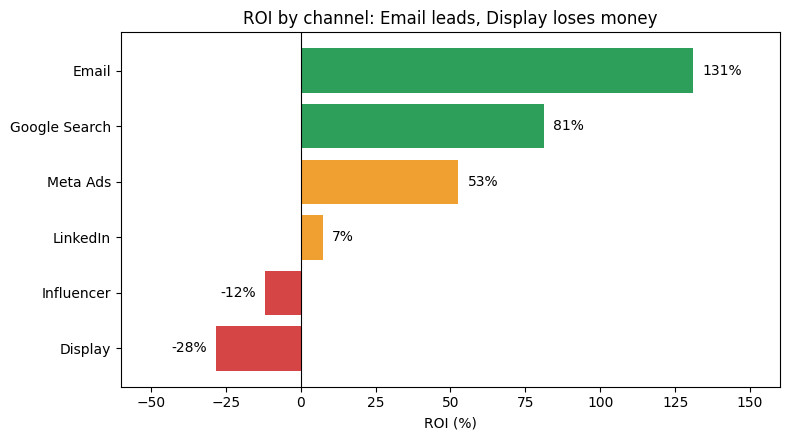

In [281]:
d = channel.sort_values("roi")

plt.figure(figsize=(8, 4.5))
plt.barh(d["channel"], d["roi"] * 100, color=d["verdict"].map(colors))
plt.axvline(0, color="black", linewidth=0.8)

for i, v in enumerate(d["roi"] * 100):
    plt.text(v + (3 if v >= 0 else -3), i, f"{v:.0f}%",
             va="center", ha="left" if v >= 0 else "right")

plt.xlim(-60, 160)
plt.title("ROI by channel: Email leads, Display loses money")
plt.xlabel("ROI (%)")
plt.tight_layout()
plt.savefig("chart1_roi_by_channel.png", dpi=200)
plt.show()

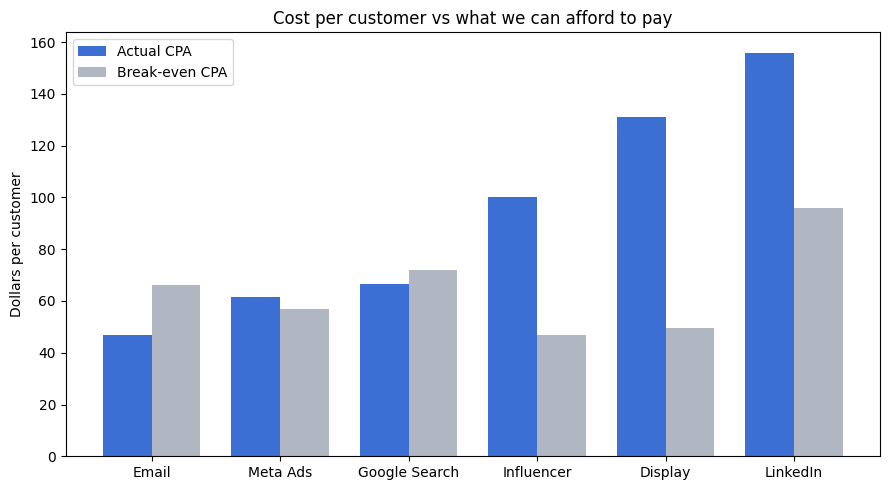

In [282]:
d = channel.sort_values("cpa")
x = np.arange(len(d))
w = 0.38

plt.figure(figsize=(9, 5))
plt.bar(x - w/2, d["cpa"], w, label="Actual CPA", color="#3b6fd4")
plt.bar(x + w/2, d["breakeven_cpa"], w, label="Break-even CPA", color="#b0b7c3")
plt.xticks(x, d["channel"])
plt.ylabel("Dollars per customer")
plt.title("Cost per customer vs what we can afford to pay")
plt.legend()
plt.tight_layout()
plt.savefig("chart2_cpa_vs_breakeven.png", dpi=200)
plt.show()

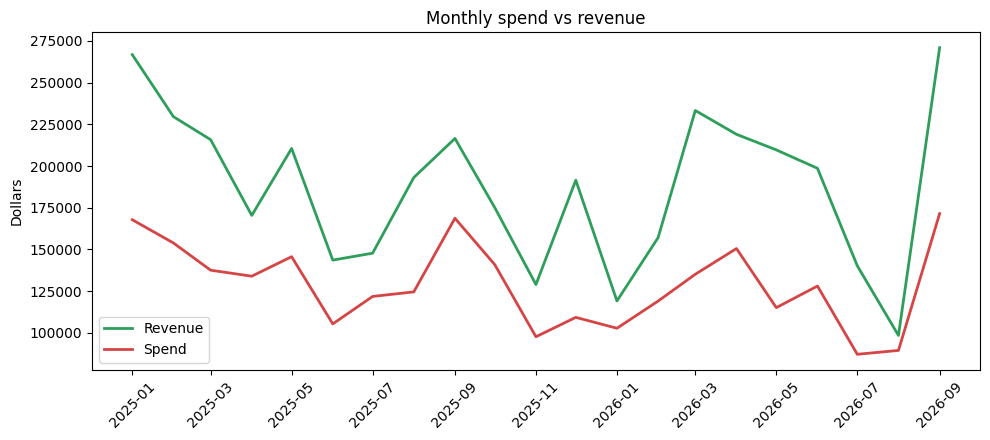

In [283]:
clean["month"] = clean["start_date"].dt.to_period("M").dt.to_timestamp()
monthly = clean.groupby("month")[["spend", "revenue"]].sum()

plt.figure(figsize=(10, 4.5))
plt.plot(monthly.index, monthly["revenue"], label="Revenue", color="#2e9e5b", linewidth=2)
plt.plot(monthly.index, monthly["spend"], label="Spend", color="#d64545", linewidth=2)
plt.title("Monthly spend vs revenue")
plt.ylabel("Dollars")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart3_monthly_trend.png", dpi=200)
plt.show()

In [284]:
import zipfile
from google.colab import files

with zipfile.ZipFile("charts.zip", "w") as z:
    for f in ["chart1_roi_by_channel.png", "chart2_cpa_vs_breakeven.png", "chart3_monthly_trend.png"]:
        z.write(f)

files.download("charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [285]:
shift_pct = 0.20
cut = ["Influencer", "Display"]
add = ["Email", "Google Search"]

sim = channel[["channel", "spend", "revenue"]].copy()
sim["roas"] = sim["revenue"] / sim["spend"]   # revenue earned per $1 spent
sim["new_spend"] = sim["spend"]

# Take money away from the weak channels
freed = 0
for c in cut:
    mask = sim["channel"] == c
    amount = sim.loc[mask, "spend"].iloc[0] * shift_pct
    sim.loc[mask, "new_spend"] -= amount
    freed += amount

# Give it equally to the strong channels
for c in add:
    sim.loc[sim["channel"] == c, "new_spend"] += freed / len(add)

# Estimate new revenue: each channel keeps earning its current revenue per $1
sim["new_revenue"] = sim["new_spend"] * sim["roas"]

print("Budget moved:           $", round(freed))
print("Total spend before:     $", round(sim["spend"].sum()))
print("Total spend after:      $", round(sim["new_spend"].sum()))
print("Total revenue before:   $", round(sim["revenue"].sum()))
print("Total revenue after:    $", round(sim["new_revenue"].sum()))
print("Revenue gained:         $", round(sim["new_revenue"].sum() - sim["revenue"].sum()))

Budget moved:           $ 157982
Total spend before:     $ 2704855
Total spend after:      $ 2704855
Total revenue before:   $ 3935850
Total revenue after:    $ 4135033
Revenue gained:         $ 199182


In [286]:
sim.to_csv("budget_simulation.csv", index=False)

Channel	Verdict	Action
Email	Scale	Increase budget, since it is the most profitable channel
Google Search	Scale	Increase budget, since CPA is below break-even
Meta Ads	Fix	Improve targeting or creative to bring CPA down from ~$61 to under $57
LinkedIn	Fix	CPA (~$156) is far above break-even ($96), so test cheaper audiences and offers
Influencer	Pause	Losing money, so cut the budget
Display	Pause	Weakest conversion rate (0.5%), so cut the budget